# 07 Big-day reactions: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded or computed here** (the file is filtered while reading; events whose look-ahead window runs past 2020-12-31 are dropped from that statistic and counted).

**Reactions are descriptions, not a trading strategy. No trading costs are applied.**

Rules (only information available at the time):
- **Big day:** SPY's daily return (percent change of adjusted close) is larger in size than 2 x the standard deviation (sample, n-1) of SPY's daily returns over the previous 63 trading days, **not including that day**. Big up = positive, big down = negative. Counted from the first day with 63 days of history.
- **Reactions (main):** SPY's return from the big day's close over the next 1, 5 and 21 trading days. **Information only:** from the NEXT day's close over 5 and 21 days.
- **Baselines:** SPY's average return over all 1-, 5- and 21-day stretches starting at every eligible day (same period, same alignment); the chance of at least one big day in the 5 days after any eligible day.
- **Sector sensitivity:** on each big down day (and, separately, big up day), each fund's same-day return minus SPY's; averaged per fund. All 22 non-SPY, non-BTC funds are shown; B3 uses only the 9 sector funds present in both halves (XLK XLE XLV XLU XLF XLI XLB XLP XLY). Halves: 1999-2009 and 2010-2020.
- **Rough 95% ranges:** big days bunch together and the windows after them overlap, so months are resampled with replacement (2,000 draws, fixed seed), keeping each calendar month's big days together.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from rotation.data import load_prices, wide
from rotation.returns import daily_returns
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)
B = 2000
SECT9 = ["XLK", "XLE", "XLV", "XLU", "XLF", "XLI", "XLB", "XLP", "XLY"]
H1_END = pd.Timestamp("2009-12-31")

## 1. Load build years only (23 symbols, no BTC-USD; adjusted close)

In [2]:
SYMS = [s for s in config.ALL_SYMBOLS if s != "BTC-USD"]
df = load_prices(symbols=SYMS, fields=["adj_close"], end=config.BUILD_END)
assert df.date.max() <= pd.Timestamp(config.BUILD_END)
P = wide(df, "adj_close")[SYMS]
n = len(P)
assert n == 5536                      # same trading calendar as notebooks 02-06
dates = P.index
ret = daily_returns(P)                # daily returns, never prices, for same-day numbers
print(dates.min().date(), "to", dates.max().date(), "|", n, "days |", len(SYMS), "symbols")

1999-01-04 to 2020-12-31 | 5536 days | 23 symbols


## 2. Big days

In [3]:
r = ret["SPY"].values; c = P["SPY"].values
sd63 = ret["SPY"].rolling(63).std().shift(1).values        # std of the previous 63 daily returns, excluding today
thr = 2 * sd63
big = np.abs(r) > thr                                         # NaN threshold -> False
up = big & (r > 0); down = big & (r < 0)
FIRST = int(np.argmax(~np.isnan(sd63)))
elig = np.zeros(n, bool); elig[FIRST:] = True
year = dates.year.values
print("first eligible day:", dates[FIRST].date(), "(position", FIRST, ") | eligible days:", int(elig.sum()))
print("big days: %d total (%.2f%% of eligible days) | big up %d | big down %d" % (big.sum(), big.sum() / elig.sum() * 100, up.sum(), down.sum()))
print("share of big days that are down: %.1f%%" % (down.sum() / big.sum() * 100))

# independent hand check with plain loops on one big down day and one non-big day
p0 = int(np.flatnonzero(down)[20])
win = [r[j] for j in range(p0 - 63, p0)]
m_ = sum(win) / 63; sd_h = (sum((x - m_) ** 2 for x in win) / 62) ** 0.5
assert abs(sd_h - sd63[p0]) < 1e-12 and abs(r[p0]) > 2 * sd_h and r[p0] < 0
q0 = FIRST + 500
while big[q0]: q0 += 1
win = [r[j] for j in range(q0 - 63, q0)]
m_ = sum(win) / 63; sd_h = (sum((x - m_) ** 2 for x in win) / 62) ** 0.5
assert abs(r[q0]) <= 2 * sd_h
print("hand check passed: big down day", dates[p0].date(), "return %.2f%% vs threshold %.2f%%" % (r[p0] * 100, 2 * sd63[p0] * 100))

# month index for resampling (eligible days only)
ym = dates.year.values * 12 + dates.month.values
months = np.unique(ym[FIRST:])
M = len(months)
mi = np.full(n, -1); mi[FIRST:] = np.searchsorted(months, ym[FIRST:])
IDX = np.random.default_rng(0).integers(0, M, size=(B, M))
print("calendar months in the eligible period:", M)

def mstats(values, sel):
    sel = sel & ~np.isnan(values) & (mi >= 0)
    s = np.bincount(mi[sel], weights=values[sel], minlength=M)
    k = np.bincount(mi[sel], minlength=M).astype(float)
    return s, k
def boot_mean(values, sel):
    s, k = mstats(values, sel)
    num = s[IDX].sum(axis=1); den = k[IDX].sum(axis=1)
    return num / np.where(den > 0, den, np.nan)
def fwd(x, k, start=0):
    # return from x[t+start] to x[t+start+k], aligned at day t; NaN where it runs past the end
    out = np.full(len(x), np.nan)
    L = len(x) - start - k
    out[:L] = x[start + k:] / x[start:start + L] - 1
    return out
def pct(a, q): return np.nanpercentile(a, q)

first eligible day: 1999-04-07 (position 64 ) | eligible days: 5472
big days: 332 total (6.07% of eligible days) | big up 150 | big down 182
share of big days that are down: 54.8%
hand check passed: big down day 2002-04-11 return -2.49% vs threshold 2.18%
calendar months in the eligible period: 261


## 3. Result 1: big days by year

In [4]:
rows = []
for y in sorted(set(year[FIRST:])):
    e = elig & (year == y)
    rows.append(dict(year=y, eligible_days=int(e.sum()), big_up=int((up & e).sum()), big_down=int((down & e).sum()),
                     big_total=int((big & e).sum()), big_share_pct=(big & e).sum() / e.sum() * 100))
by_year = pd.DataFrame(rows)
tot = dict(year="All", eligible_days=by_year.eligible_days.sum(), big_up=by_year.big_up.sum(), big_down=by_year.big_down.sum(), big_total=by_year.big_total.sum(),
           big_share_pct=by_year.big_total.sum() / by_year.eligible_days.sum() * 100)
by_year = pd.concat([by_year, pd.DataFrame([tot])], ignore_index=True)
by_year.round(2).to_csv(R / "07_big_days_by_year.csv", index=False)
print(by_year.round(2).to_string(index=False))
print("\nmost big-down years:", by_year[by_year.year != "All"].sort_values("big_down", ascending=False).head(5)[["year", "big_down"]].values.tolist())

year  eligible_days  big_up  big_down  big_total  big_share_pct
1999            188       4         5          9           4.79
2000            252      10         8         18           7.14
2001            248       6         5         11           4.44
2002            252       9         7         16           6.35
2003            252       3         3          6           2.38
2004            252       3         8         11           4.37
2005            252       8         9         17           6.75
2006            251       8         8         16           6.37
2007            251       9        15         24           9.56
2008            253       9        11         20           7.91
2009            252       4         2          6           2.38
2010            252       7         9         16           6.35
2011            252       5        14         19           7.54
2012            250       9         6         15           6.00
2013            252       6         7   

## 4. Result 2: bunching (B1)
For each big day, did at least one more big day occur among the next 5 trading days? Baseline = the same question asked after every eligible day (the chance that a 5-day stretch contains at least one big day). Big days whose next 5 days run past 2020-12-31 are dropped and counted.

In [5]:
any5 = np.full(n, np.nan)
for t in range(FIRST, n - 5):
    any5[t] = float(big[t + 1:t + 6].any())
base_share = np.nanmean(any5[elig])
bb = boot_mean(any5, elig)
rows = []
for g, sel in [("any big day", big), ("big down day", down), ("big up day", up)]:
    ok = sel & ~np.isnan(any5)
    sh = any5[ok].mean(); bs = boot_mean(any5, sel)
    ratio_bs = bs / bb
    rows.append(dict(after=g, events=int(ok.sum()), dropped_no_5_days=int((sel & np.isnan(any5)).sum()), share_with_another_big_day_pct=sh * 100,
                     range95_low_pct=pct(bs, 2.5) * 100, range95_high_pct=pct(bs, 97.5) * 100, baseline_pct=base_share * 100,
                     baseline_range95_low_pct=pct(bb, 2.5) * 100, baseline_range95_high_pct=pct(bb, 97.5) * 100,
                     ratio=sh / base_share, ratio_range95_low=pct(ratio_bs, 2.5), ratio_range95_high=pct(ratio_bs, 97.5)))
t_b1 = pd.DataFrame(rows)
t_b1.round(3).to_csv(R / "07_bunching.csv", index=False)
print(t_b1.round(3).to_string(index=False))
print("\nB1: ratio %.2f (needs >= 2.0); %.1f%% of big days are followed by another within 5 days vs %.1f%% of 5-day stretches" % (
    t_b1.ratio.iloc[0], t_b1.share_with_another_big_day_pct.iloc[0], base_share * 100))
# extra context (not a prediction): the same ratio when the next 5 days exclude the following day, and by half
for lab, per in [("1999-2009", dates <= H1_END), ("2010-2020", dates > H1_END)]:
    ok = big & ~np.isnan(any5) & per; okb = elig & ~np.isnan(any5) & per
    print("  %s: %d big days, %.1f%% followed by another vs baseline %.1f%% (ratio %.2f)" % (lab, ok.sum(), any5[ok].mean() * 100, any5[okb].mean() * 100, any5[ok].mean() / any5[okb].mean()))

       after  events  dropped_no_5_days  share_with_another_big_day_pct  range95_low_pct  range95_high_pct  baseline_pct  baseline_range95_low_pct  baseline_range95_high_pct  ratio  ratio_range95_low  ratio_range95_high
 any big day     332                  0                          47.590           40.680            53.461        23.175                    20.303                     26.165  2.053              1.773               2.377
big down day     182                  0                          58.242           50.000            65.829        23.175                    20.303                     26.165  2.513              2.146               2.938
  big up day     150                  0                          34.667           25.973            42.556        23.175                    20.303                     26.165  1.496              1.122               1.878

B1: ratio 2.05 (needs >= 2.0); 47.6% of big days are followed by another within 5 days vs 23.2% of 5-day stretches
  19

## 5. Result 3: SPY reactions after big down and big up days (B2)
Return from the big day's close over the next 1, 5 and 21 trading days (main). Baseline = the same stretch from every eligible day. Rough ranges resample calendar months. Next-day-start versions (from the NEXT day's close over 5 and 21 days) are information only.

In [6]:
def react_table(version, start, horizons):
    rows = []
    for h in horizons:
        v = fwd(c, h, start)
        okb = elig & ~np.isnan(v)
        bbm = boot_mean(v, elig)
        for g, sel in [("big down", down), ("big up", up)]:
            ok = sel & ~np.isnan(v); x = v[ok]
            bs = boot_mean(v, sel)
            rows.append(dict(version=version, group=g, horizon_days=h, count=int(ok.sum()), dropped=int((sel & np.isnan(v)).sum()),
                             avg_pct=x.mean() * 100, median_pct=np.median(x) * 100, share_positive_pct=(x > 0).mean() * 100,
                             range95_low_pct=pct(bs, 2.5) * 100, range95_high_pct=pct(bs, 97.5) * 100,
                             baseline_avg_pct=v[okb].mean() * 100, baseline_median_pct=np.median(v[okb]) * 100, baseline_share_positive_pct=(v[okb] > 0).mean() * 100,
                             baseline_range95_low_pct=pct(bbm, 2.5) * 100, baseline_range95_high_pct=pct(bbm, 97.5) * 100,
                             avg_minus_baseline_pts=(x.mean() - v[okb].mean()) * 100, diff_range95_low=pct(bs - bbm, 2.5) * 100, diff_range95_high=pct(bs - bbm, 97.5) * 100))
    return pd.DataFrame(rows)
t_main = react_table("from the big day's close (main)", 0, (1, 5, 21))
t_next = react_table("from the NEXT day's close (information only)", 1, (5, 21))
t3 = pd.concat([t_main, t_next], ignore_index=True)
t3.round(3).to_csv(R / "07_spy_reactions.csv", index=False)
cols = ["group", "horizon_days", "count", "dropped", "avg_pct", "median_pct", "share_positive_pct", "range95_low_pct", "range95_high_pct", "baseline_avg_pct", "baseline_share_positive_pct", "avg_minus_baseline_pts", "diff_range95_low", "diff_range95_high"]
print("MAIN (from the big day's close):"); print(t_main[cols].round(2).to_string(index=False))
print("\nINFORMATION ONLY (from the NEXT day's close):"); print(t_next[cols].round(2).to_string(index=False))
print("\nB2: 5-day average after big down days %.3f%% vs baseline %.3f%% (needs above)" % (
    t_main[(t_main.group == "big down") & (t_main.horizon_days == 5)].avg_pct.iloc[0], t_main[(t_main.group == "big down") & (t_main.horizon_days == 5)].baseline_avg_pct.iloc[0]))

MAIN (from the big day's close):
   group  horizon_days  count  dropped  avg_pct  median_pct  share_positive_pct  range95_low_pct  range95_high_pct  baseline_avg_pct  baseline_share_positive_pct  avg_minus_baseline_pts  diff_range95_low  diff_range95_high
big down             1    182        0     0.23        0.22               58.79            -0.02              0.48              0.03                        54.34                    0.19             -0.06               0.45
  big up             1    150        0    -0.21        0.01               50.67            -0.54              0.07              0.03                        54.34                   -0.24             -0.57               0.03
big down             5    182        0     0.10        0.37               55.49            -0.67              0.68              0.16                        57.47                   -0.07             -0.80               0.49
  big up             5    150        0    -0.25        0.27               5

## 6. Result 4: year by year, average 5-day reaction after big down days (with counts)

In [7]:
v5 = fwd(c, 5, 0)
rows = []
for y in sorted(set(year[FIRST:])):
    e = elig & (year == y)
    sel = down & e; ok = sel & ~np.isnan(v5); okb = e & ~np.isnan(v5)
    rows.append(dict(year=y, big_down_days=int(sel.sum()), with_5_days=int(ok.sum()),
                     avg_5day_pct=v5[ok].mean() * 100 if ok.any() else np.nan, median_5day_pct=np.median(v5[ok]) * 100 if ok.any() else np.nan,
                     share_positive_pct=(v5[ok] > 0).mean() * 100 if ok.any() else np.nan,
                     baseline_avg_5day_pct=v5[okb].mean() * 100, avg_minus_baseline_pts=(v5[ok].mean() - v5[okb].mean()) * 100 if ok.any() else np.nan))
yy = pd.DataFrame(rows)
yy.round(3).to_csv(R / "07_big_down_5day_by_year.csv", index=False)
print(yy.round(2).to_string(index=False))
have = yy.dropna(subset=["avg_5day_pct"])
print("\nyears with at least one big down day:", len(have), "| years where the 5-day average beat that year's baseline:", int((have.avg_minus_baseline_pts > 0).sum()),
      "| years with 3+ big down days:", int((have.with_5_days >= 3).sum()), "of which beat baseline:", int(((have.with_5_days >= 3) & (have.avg_minus_baseline_pts > 0)).sum()))

 year  big_down_days  with_5_days  avg_5day_pct  median_5day_pct  share_positive_pct  baseline_avg_5day_pct  avg_minus_baseline_pts
 1999              5            5          0.11            -0.33               40.00                   0.19                   -0.08
 2000              8            8          2.21             3.50               62.50                  -0.09                    2.30
 2001              5            5         -0.35            -0.35               40.00                  -0.17                   -0.18
 2002              7            7         -0.46            -0.60               42.86                  -0.38                   -0.08
 2003              3            3          0.65             0.96               66.67                   0.46                    0.19
 2004              8            8          0.03             0.24               62.50                   0.16                   -0.13
 2005              9            9          0.12             0.21            

## 7. Result 5: sector sensitivity on big down and big up days (B3)
Each fund's same-day return minus SPY's, averaged over the big days (days where both exist), for the full period and each half. B3 = Spearman rank correlation of the 9 sector funds' half averages (1999-2009 vs 2010-2020); the rough range resamples calendar months within each half.

In [8]:
FUNDS = [s for s in SYMS if s != "SPY"]
h1 = dates <= H1_END; h2 = ~h1
EX = {s: ret[s].values - r for s in FUNDS}

def sensitivity(sel):
    rows = []
    for s in FUNDS:
        ex = EX[s]; ok = sel & ~np.isnan(ex)
        row = dict(fund=s, group=config.GROUP[s])
        for lab, per in [("full", np.ones(n, bool)), ("1999_2009", h1), ("2010_2020", h2)]:
            o = ok & per
            row[f"avg_pct_{lab}"] = ex[o].mean() * 100 if o.any() else np.nan
            row[f"n_{lab}"] = int(o.sum())
        o = ok
        row["median_pct_full"] = np.median(ex[o]) * 100 if o.any() else np.nan
        row["share_below_SPY_full_pct"] = (ex[o] < 0).mean() * 100 if o.any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

def rank_corr_boot(sel, seed=1):
    # Spearman between the half averages of the 9 sectors; months resampled within each half
    rng = np.random.default_rng(seed)
    avgs = []
    for per in (h1, h2):
        mon = np.unique(mi[elig & per]); Mh = len(mon)
        loc = np.full(n, -1); loc[elig & per] = np.searchsorted(mon, mi[elig & per])
        ix = rng.integers(0, Mh, size=(B, Mh))
        mat = np.zeros((B, len(SECT9)))
        for j, s in enumerate(SECT9):
            ok = sel & per & elig & ~np.isnan(EX[s])
            ssum = np.bincount(loc[ok], weights=EX[s][ok], minlength=Mh); k = np.bincount(loc[ok], minlength=Mh).astype(float)
            den = k[ix].sum(axis=1)
            mat[:, j] = ssum[ix].sum(axis=1) / np.where(den > 0, den, np.nan)
        avgs.append(mat)
    a1, a2 = avgs
    good = ~(np.isnan(a1).any(axis=1) | np.isnan(a2).any(axis=1))
    a1, a2 = a1[good], a2[good]
    rk = lambda a: np.argsort(np.argsort(a, axis=1), axis=1).astype(float)
    r1, r2 = rk(a1), rk(a2)
    r1 -= r1.mean(axis=1, keepdims=True); r2 -= r2.mean(axis=1, keepdims=True)
    rho = (r1 * r2).sum(axis=1) / np.sqrt((r1 ** 2).sum(axis=1) * (r2 ** 2).sum(axis=1))
    return pct(rho, 2.5), pct(rho, 97.5), int(good.sum())

out = {}
for lab, sel in [("down", down), ("up", up)]:
    sens = sensitivity(sel)
    sens.round(3).to_csv(R / f"07_sector_sensitivity_big_{lab}.csv", index=False)
    s9 = sens.set_index("fund").loc[SECT9]
    rho = s9.avg_pct_1999_2009.corr(s9.avg_pct_2010_2020, method="spearman")
    lo, hi, ng = rank_corr_boot(sel)
    out[lab] = (sens, rho, lo, hi, ng, s9)
    cnt = {"full": int(sel.sum()), "1999-2009": int((sel & h1).sum()), "2010-2020": int((sel & h2).sum())}
    print("=== big %s days: %s ===" % (lab, cnt))
    print(sens.sort_values("avg_pct_full").round(2).to_string(index=False))
    print("9-sector Spearman rank correlation between halves: %.3f (rough 95%% range %.2f to %.2f, %d usable draws)\n" % (rho, lo, hi, ng))
rb = pd.DataFrame([dict(day_type=f"big {k}", spearman_1999_2009_vs_2010_2020=v[1], range95_low=v[2], range95_high=v[3], sectors=len(SECT9),
                        big_days_1999_2009=int((sel_ & h1).sum()), big_days_2010_2020=int((sel_ & h2).sum()))
                   for (k, v), sel_ in zip(out.items(), [down, up])])
rb.round(3).to_csv(R / "07_b3_rank_correlation.csv", index=False)
s9 = out["down"][5]
order1 = s9.avg_pct_1999_2009.sort_values().index.tolist(); order2 = s9.avg_pct_2010_2020.sort_values().index.tolist()
print("big down days, 9 sectors ordered from most to least negative vs SPY:\n  1999-2009:", order1, "\n  2010-2020:", order2)
print("\nB3: Spearman %.3f (needs >= 0.5)" % out["down"][1])

=== big down days: {'full': 182, '1999-2009': 81, '2010-2020': 101} ===
fund        group  avg_pct_full  n_full  avg_pct_1999_2009  n_1999_2009  avg_pct_2010_2020  n_2010_2020  median_pct_full  share_below_SPY_full_pct
 XLF       sector         -0.55     182              -0.71           81              -0.43          101            -0.27                     70.88
 KRE     industry         -0.54     130              -0.51           29              -0.54          101            -0.33                     61.54
 EEM other market         -0.51     156              -1.15           55              -0.16          101            -0.43                     65.38
 SMH     industry         -0.39     173              -0.13           72              -0.58          101            -0.35                     64.16
 XBI     industry         -0.33     135               0.56           34              -0.63          101            -0.35                     63.70
 XLE       sector         -0.31     182       

## 8. Information only: TLT (long-term Treasury bonds), GLD (gold) and UUP (US dollar) on big down days

In [9]:
rows = []
for fnd in ["TLT", "GLD", "UUP"]:
    xr = ret[fnd].values; v = fwd(P[fnd].values, 5, 0)
    first_day = dates[np.flatnonzero(~np.isnan(xr))[0]].date()
    for g, sel in [("big down days", down), ("big up days", up)]:
        ok1 = sel & ~np.isnan(xr); ok5 = sel & ~np.isnan(v); okb = elig & ~np.isnan(v); okb1 = elig & ~np.isnan(xr)
        b5 = boot_mean(v, sel); bb5 = boot_mean(v, elig)
        rows.append(dict(fund=fnd, first_return_date=first_day, day_type=g, big_days_with_data=int(ok1.sum()),
                         same_day_avg_pct=xr[ok1].mean() * 100, same_day_median_pct=np.median(xr[ok1]) * 100, same_day_share_positive_pct=(xr[ok1] > 0).mean() * 100,
                         all_days_avg_daily_pct=xr[okb1].mean() * 100,
                         next5_count=int(ok5.sum()), next5_avg_pct=v[ok5].mean() * 100, next5_median_pct=np.median(v[ok5]) * 100, next5_share_positive_pct=(v[ok5] > 0).mean() * 100,
                         next5_range95_low_pct=pct(b5, 2.5) * 100, next5_range95_high_pct=pct(b5, 97.5) * 100,
                         baseline_5day_avg_pct=v[okb].mean() * 100, avg_minus_baseline_pts=(v[ok5].mean() - v[okb].mean()) * 100))
t6 = pd.DataFrame(rows)
t6.round(3).to_csv(R / "07_tlt_gld_uup.csv", index=False)
print(t6.round(2).to_string(index=False))

fund first_return_date      day_type  big_days_with_data  same_day_avg_pct  same_day_median_pct  same_day_share_positive_pct  all_days_avg_daily_pct  next5_count  next5_avg_pct  next5_median_pct  next5_share_positive_pct  next5_range95_low_pct  next5_range95_high_pct  baseline_5day_avg_pct  avg_minus_baseline_pts
 TLT        2002-07-31 big down days                 157              0.85                 0.81                        78.34                    0.03          157          -0.07              0.14                     53.50                  -0.44                    0.31                   0.16                   -0.22
 TLT        2002-07-31   big up days                 123             -0.73                -0.58                        24.39                    0.03          123           0.15             -0.05                     49.59                  -0.31                    0.55                   0.16                   -0.01
 GLD        2004-11-19 big down days                 14

## 9. Chart: average path of SPY over the 21 days after big down days, big up days and all days

events with a full 21 days after: big down 182 of 182, big up 150 of 150, all eligible days 5451
day 21: big down 0.44% (range -0.99 to 1.62) | big up 0.22% (-0.84 to 1.18) | all days 0.66% (0.17 to 1.10)


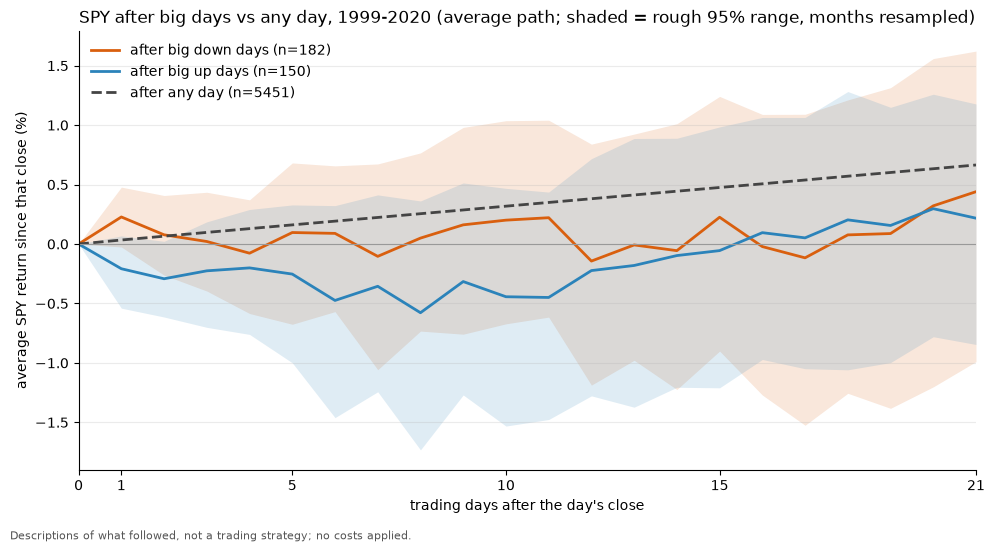

In [10]:
K = 21
paths = np.full((n, K + 1), np.nan)
for k in range(K + 1):
    paths[:n - k, k] = c[k:] / c[:n - k] - 1
valid = ~np.isnan(paths[:, K])
def path_stats(sel):
    sv = sel & valid & (mi >= 0)
    avg = paths[sv].mean(axis=0)
    S = np.zeros((M, K + 1)); np.add.at(S, mi[sv], paths[sv]); k = np.bincount(mi[sv], minlength=M).astype(float)
    num = S[IDX].sum(axis=1); den = k[IDX].sum(axis=1)[:, None]
    bs = num / np.where(den > 0, den, np.nan)
    return avg * 100, np.nanpercentile(bs, 2.5, axis=0) * 100, np.nanpercentile(bs, 97.5, axis=0) * 100, int(sv.sum())
pd_, pd_lo, pd_hi, nd = path_stats(down)
pu_, pu_lo, pu_hi, nu = path_stats(up)
pa_, pa_lo, pa_hi, na = path_stats(elig)
print("events with a full 21 days after: big down %d of %d, big up %d of %d, all eligible days %d" % (nd, down.sum(), nu, up.sum(), na))
pd.DataFrame(dict(day=range(K + 1), big_down_avg_pct=pd_, big_down_lo=pd_lo, big_down_hi=pd_hi, big_up_avg_pct=pu_, big_up_lo=pu_lo, big_up_hi=pu_hi,
                  all_days_avg_pct=pa_, all_days_lo=pa_lo, all_days_hi=pa_hi)).round(3).to_csv(R / "07_avg_path_after_big_days.csv", index=False)
print("day 21: big down %.2f%% (range %.2f to %.2f) | big up %.2f%% (%.2f to %.2f) | all days %.2f%% (%.2f to %.2f)" % (pd_[-1], pd_lo[-1], pd_hi[-1], pu_[-1], pu_lo[-1], pu_hi[-1], pa_[-1], pa_lo[-1], pa_hi[-1]))
x = np.arange(K + 1)
fig, ax = plt.subplots(figsize=(10, 5.5))
for avg, lo, hi, col, lab in [(pd_, pd_lo, pd_hi, "#d95f0e", f"after big down days (n={nd})"), (pu_, pu_lo, pu_hi, "#2b83ba", f"after big up days (n={nu})")]:
    ax.fill_between(x, lo, hi, color=col, alpha=0.15, lw=0)
    ax.plot(x, avg, color=col, lw=2, label=lab)
ax.plot(x, pa_, color="#444444", lw=2, ls="--", label=f"after any day (n={na})")
ax.axhline(0, color="#999999", lw=0.8)
ax.set_xlim(0, K); ax.set_xticks([0, 1, 5, 10, 15, 21])
ax.set_xlabel("trading days after the day's close"); ax.set_ylabel("average SPY return since that close (%)")
ax.set_title("SPY after big days vs any day, 1999-2020 (average path; shaded = rough 95% range, months resampled)")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, 0.01, "Descriptions of what followed, not a trading strategy; no costs applied.", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(R / "07_avg_path_after_big_days.png", dpi=130)
plt.show()

## 10. Observations file and summary of what is judged

In [11]:
v1, v5_, v21 = fwd(c, 1), fwd(c, 5), fwd(c, 21)
obs = pd.DataFrame(dict(date=dates, spy_return=r, threshold_2sd=thr, kind=np.where(up, "big up", np.where(down, "big down", "")),
                        another_big_day_next5=any5, spy_next1=v1, spy_next5=v5_, spy_next21=v21))
obs = obs[big].copy()
obs.to_csv(R / "07_big_days.csv", index=False)
print("saved", len(obs), "big days")
b1 = t_b1.iloc[0]
print("B1: %.1f%% vs %.1f%% -> ratio %.2f (needs >= 2.0)" % (b1.share_with_another_big_day_pct, b1.baseline_pct, b1.ratio))
dd = t_main[(t_main.group == "big down") & (t_main.horizon_days == 5)].iloc[0]
print("B2: %.3f%% vs baseline %.3f%% (needs above)" % (dd.avg_pct, dd.baseline_avg_pct))
print("B3: Spearman %.3f (needs >= 0.5)" % out["down"][1])

saved 332 big days
B1: 47.6% vs 23.2% -> ratio 2.05 (needs >= 2.0)
B2: 0.097% vs baseline 0.162% (needs above)
B3: Spearman 0.783 (needs >= 0.5)
